# Customer Segmentation & SQL Analytics

Data: **UCI Online Retail II**, every transaction of a UK-based online gift retailer (many customers are wholesalers), Dec 2009 – Dec 2011.

This notebook walks through the analysis; the same logic runs end-to-end with `python -m src.pipeline`.

In [1]:
import sys; sys.path.insert(0, '..')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src.sql_runner import connect, build_sales, query
from src.segment import FEATURES, scale, evaluate_k, choose_k, segment, profile
sns.set_theme(style='whitegrid')
con = connect()
build_sales(con)

## 1. Data quality: what the cleaning step removes
Rules live in `sql/01_clean.sql`. A row can break more than one rule.

In [2]:
query(con, '02_data_quality')

,check_name,n_rows
0,raw rows,1067371
1,cancelled invoices,19494
2,quantity <= 0,22950
3,price <= 0,6207
4,missing customer_id,243007
5,non-product stock code,6093
6,exact duplicate rows,34335
7,clean rows,776577


## 2. Sales trends (SQL: `03_monthly_revenue.sql`)
December 2011 is flagged as partial (data ends on the 9th).

In [3]:
monthly = query(con, '03_monthly_revenue')
monthly.tail(8)

,month,revenue,orders,active_customers,avg_order_value,revenue_mom_pct,is_partial_month
17,2011-05-01,659242.49,1544,1054,426.97,45.1,False
18,2011-06-01,653264.92,1390,990,469.97,-0.9,False
19,2011-07-01,591603.79,1321,946,447.85,-9.4,False
20,2011-08-01,635514.38,1267,933,501.59,7.4,False
21,2011-09-01,938752.63,1739,1259,539.82,47.7,False
22,2011-10-01,1002326.56,1903,1361,526.71,6.8,False
23,2011-11-01,1136534.00,2642,1660,430.18,13.4,False
24,2011-12-01,512228.08,776,614,660.09,-54.9,True


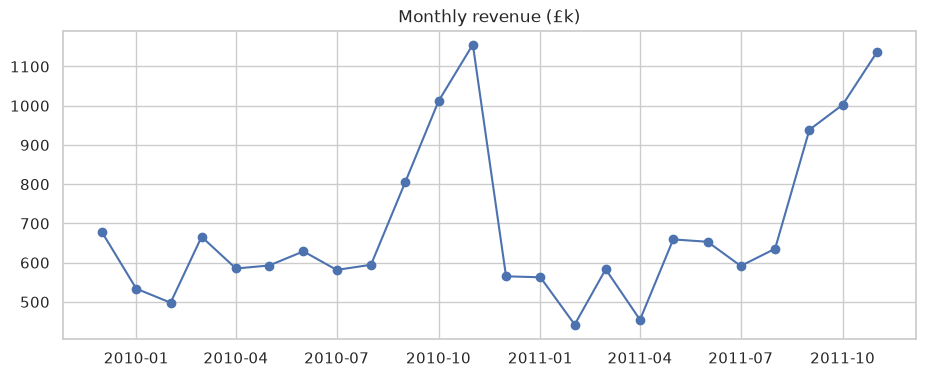

In [4]:
m = monthly[~monthly.is_partial_month]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(m.month, m.revenue / 1e3, marker='o')
ax.set_title('Monthly revenue (£k)'); plt.show()

Strong Q4 seasonality: revenue peaks every November (gift retailer, Christmas stocking).

## 3. Top countries and products (SQL window functions)

In [5]:
query(con, '05_top_countries').head(5)

,country,customers,revenue,revenue_share_pct,cumulative_share_pct
0,United Kingdom,5334,14288758.75,83.71,83.71
1,EIRE,3,586626.08,3.44,87.15
2,Netherlands,22,549773.41,3.22,90.37
3,Germany,107,383289.00,2.25,92.62
4,France,93,309403.16,1.81,94.43


In [6]:
query(con, '04_top_products').head(10)

,stock_code,description,units_sold,revenue,revenue_share_pct,revenue_rank
0,22423,REGENCY CAKESTAND 3 TIER,24124.0,277656.25,1.63,1
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,91814.0,247203.36,1.45,2
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995.0,168469.60,0.99,3
3,85099B,JUMBO BAG RED RETROSPOT,93436.0,167920.64,0.98,4
4,84879,ASSORTED COLOUR BIRD ORNAMENT,78234.0,124351.86,0.73,5
5,47566,PARTY BUNTING,23460.0,103283.38,0.61,6
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916.0,81416.73,0.48,7
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,28380.0,76598.18,0.45,8
8,79321,CHILLI LIGHTS,14843.0,69084.30,0.40,9
9,22386,JUMBO BAG PINK POLKADOT,37338.0,67769.76,0.40,10


## 4. Cohort retention (SQL: `06_cohort_retention.sql`)

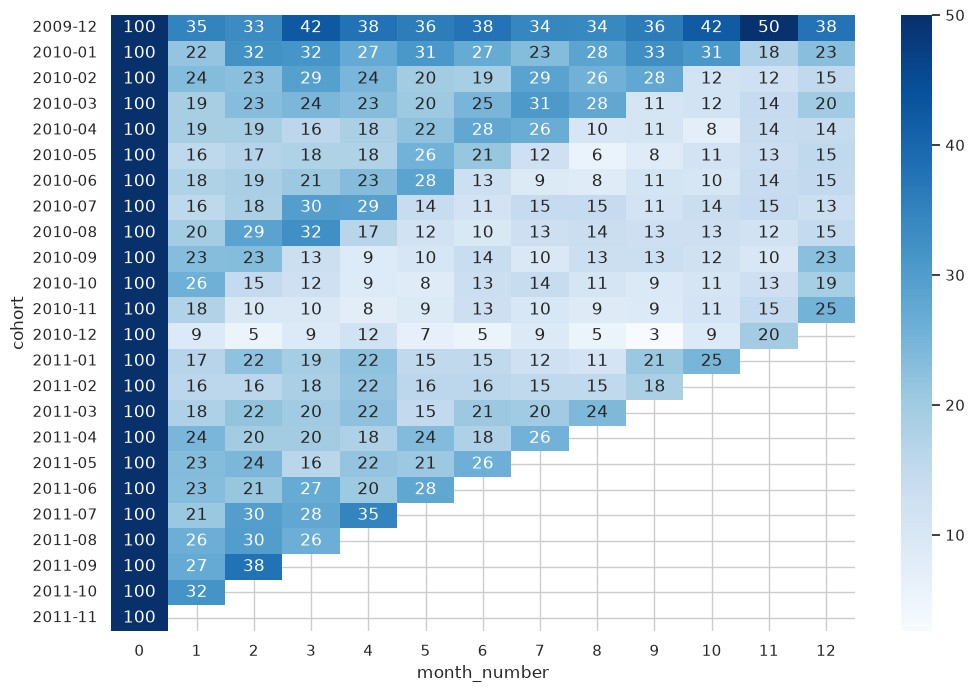

In [7]:
cohorts = query(con, '06_cohort_retention')
grid = cohorts[cohorts.month_number <= 12].assign(cohort=lambda d: d.cohort_month.dt.strftime('%Y-%m')).pivot(index='cohort', columns='month_number', values='retention_pct')
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(grid, annot=True, fmt='.0f', cmap='Blues', vmax=50, ax=ax); plt.show()

In [8]:
m1 = cohorts[(cohorts.month_number == 1) & (cohorts.cohort_month > '2009-12-01')]
print(f'Average month-1 retention (excluding the 2009-12 cohort): {m1.retention_pct.mean():.1f}%')

Average month-1 retention (excluding the 2009-12 cohort): 20.7%


The 2009-12 cohort retains far better than later ones because the data starts in Dec 2009: it contains *existing* loyal customers, not just new ones (left-censoring).

## 5. RFM features (SQL: `07_rfm.sql`)

In [9]:
rfm = query(con, '07_rfm')
rfm[FEATURES].describe().round(1)

,recency_days,frequency,monetary
count,5852.0,5852.0,5852.0
mean,200.7,6.3,2916.7
std,208.5,12.7,14306.9
min,1.0,1.0,3.0
25%,26.0,1.0,339.6
50%,96.0,3.0,856.0
75%,380.0,7.0,2241.0
max,739.0,373.0,580987.0


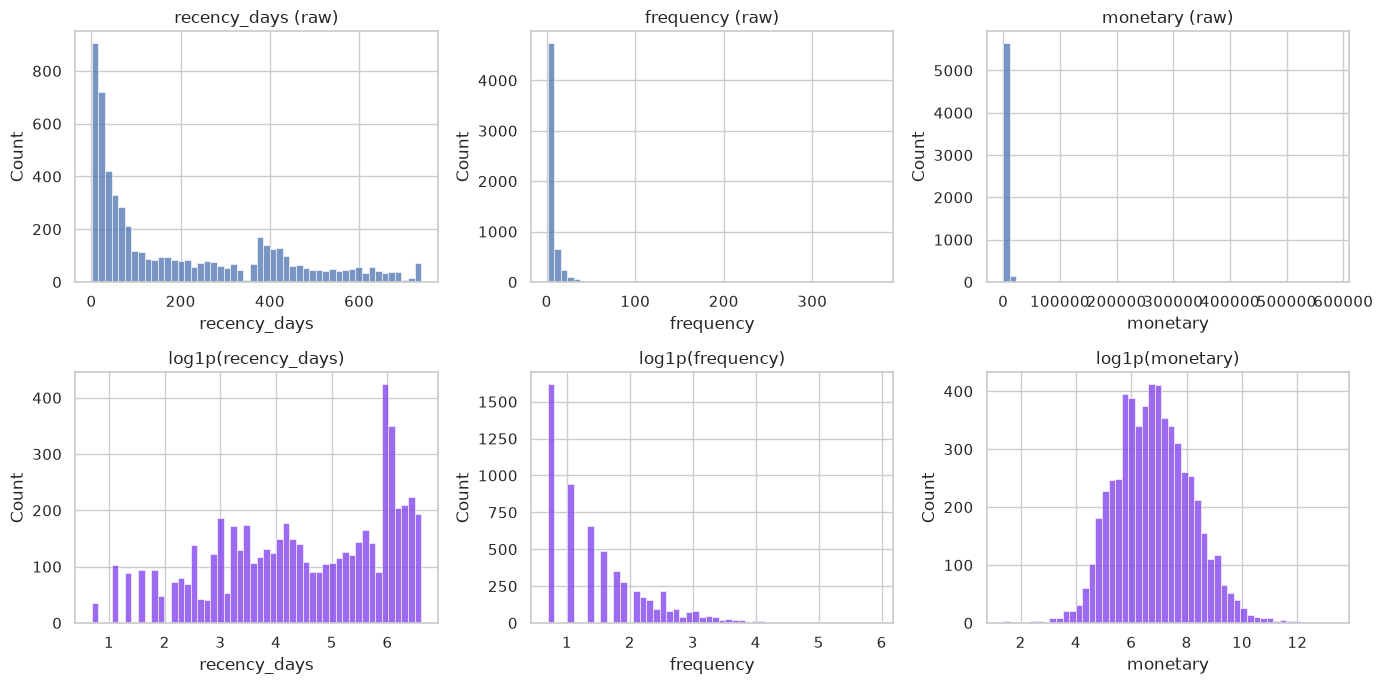

skewness raw: {'recency_days': 0.89, 'frequency': 12.04, 'monetary': 25.33}
skewness log: {'recency_days': -0.45, 'frequency': 1.0, 'monetary': 0.27}


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, f in enumerate(FEATURES):
    sns.histplot(rfm[f], bins=50, ax=axes[0, i]).set_title(f'{f} (raw)')
    sns.histplot(np.log1p(rfm[f]), bins=50, ax=axes[1, i], color='#7c3aed').set_title(f'log1p({f})')
plt.tight_layout(); plt.show()
print('skewness raw:', rfm[FEATURES].skew().round(2).to_dict())
print('skewness log:', np.log1p(rfm[FEATURES]).skew().round(2).to_dict())

Frequency and monetary are extremely right-skewed (a few wholesalers). K-Means uses Euclidean distance, so we log-transform and then standardise; otherwise monetary would dominate the clusters.

## 6. Choosing k

In [11]:
X = scale(rfm)
scores = evaluate_k(X)
k = choose_k(scores)
print('chosen k =', k)
scores.round(3)

chosen k = 4


,k,inertia,silhouette
0,2,8550.155,0.438
1,3,6320.361,0.348
2,4,4881.994,0.366
3,5,4061.586,0.346
4,6,3528.964,0.337
5,7,3164.043,0.314
6,8,2879.234,0.296
7,9,2632.660,0.288
8,10,2443.111,0.289


k=2 has the highest silhouette but only separates 'good' from 'bad' customers, which is too coarse to act on. Among k ≥ 3, **k=4** has the best silhouette and sits at the elbow of the inertia curve.

## 7. Segments

In [12]:
seg, _, _ = segment(rfm)
prof = profile(seg)
prof.drop(columns='action')

,customers,median_recency_days,median_frequency,median_monetary,total_revenue,customer_share_pct,revenue_share_pct
segment,,,,,,,
Champions,1191,17.0,13.0,4890.1,12547595.5,20.4,73.5
At Risk,1447,185.0,4.0,1450.0,2847791.4,24.7,16.7
New / Promising,1260,24.0,3.0,716.5,1055624.9,21.5,6.2
Hibernating,1954,402.0,1.0,273.3,617556.3,33.4,3.6


In [13]:
for name, row in prof.iterrows():
    print(f'{name}: {row.customers} customers ({row.customer_share_pct}%), {row.revenue_share_pct}% of revenue\n  -> {row.action}\n')

Champions: 1191 customers (20.4%), 73.5% of revenue
  -> Reward and retain: VIP/loyalty perks, early access to new ranges, referral incentives. Do not over-discount.

At Risk: 1447 customers (24.7%), 16.7% of revenue
  -> Win-back now: personalised 'we miss you' campaign with a meaningful offer; high past value justifies spend.

New / Promising: 1260 customers (21.5%), 6.2% of revenue
  -> Onboarding journey: welcome series and a time-limited offer on the next order to build the buying habit.

Hibernating: 1954 customers (33.4%), 3.6% of revenue
  -> Low-cost automated reactivation only; suppress from expensive channels.



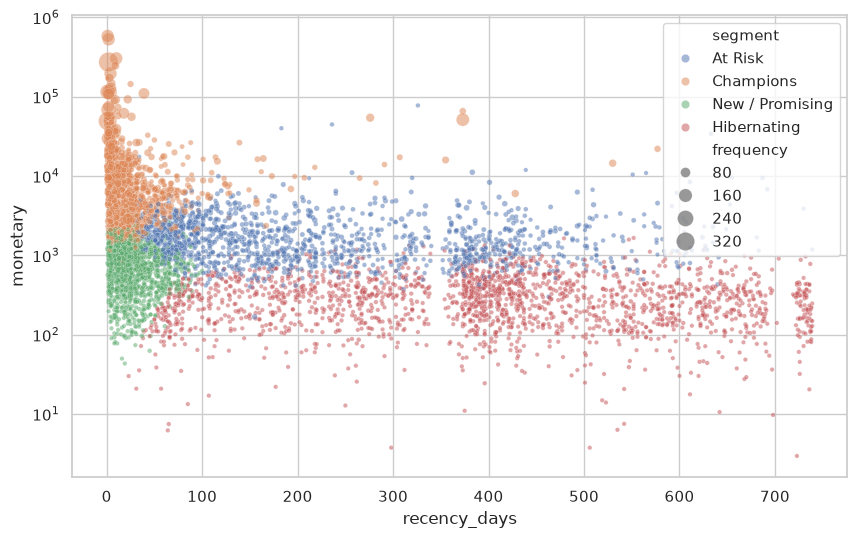

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=seg, x='recency_days', y='monetary', hue='segment', size='frequency', sizes=(10, 200), alpha=0.5, ax=ax)
ax.set_yscale('log'); plt.show()

## 8. Key takeaways
- **Champions** (~20% of customers) generate ~74% of revenue: protect them with loyalty perks rather than discounts.
- **At Risk** customers spent a lot historically but haven't bought for ~6 months (median 185 days): the highest-ROI win-back target.
- **New / Promising** customers are recent but low-frequency: onboarding journeys should convert them into repeat buyers.
- **Hibernating** customers (a third of the base, ~4% of revenue) should only receive low-cost automated campaigns.